<a href="https://colab.research.google.com/github/VinayakMokashi/brain-tumor-detection-localization/blob/main/Brain_Tumor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Brain Tumor Detection & Localization

**Author:** Vinayak Mokashi

**Based on:** the brain tumor case study ("AI in Healthcare") by Dr. Ryan Ahmed in the Udemy course *Modern Artificial Intelligence Masterclass: Build 6 Projects*. The evaluation cells below load the pre-trained weights that came with the course; this notebook does not train either model.

A two-stage deep-learning pipeline that first **detects** whether a brain MRI scan contains a tumor (a ResNet50 transfer-learning classifier) and then **localizes** it at the pixel level (a ResUNet segmentation model).

| Stage | Model | Task | Result |
| --- | --- | --- | --- |
| 1 | ResNet50 (transfer learning) | Is a tumor present? (classification) | 98.1% test accuracy with the course's pre-trained weights (slice-level split) |
| 2 | ResUNet + Focal Tversky loss | Where is it? (segmentation) | Pixel-level tumor masks |

**Dataset:** [LGG MRI Segmentation](https://www.kaggle.com/mateuszbuda/lgg-mri-segmentation) — 3,929 FLAIR MRI slices with hand-annotated tumor masks.

> The custom data generator, segmentation loss functions and end-to-end inference helper used below live in [`utilities.py`](utilities.py). A full write-up is in [`docs/PROJECT_REPORT.md`](docs/PROJECT_REPORT.md).

## 1. Problem Statement & Business Motivation

Detecting and localizing brain tumors from MRI scans is time-consuming and depends on scarce radiologist expertise. The goal of this project is a system that answers two questions automatically for every scan:

1. **Detection** — is a tumor present?
2. **Localization** — if so, *where* is it, at pixel-level precision?

A single model does neither job well on its own, so the pipeline chains two together: a fast **ResNet50 classifier** screens every scan, and only the scans it flags as positive are passed to a heavier **ResUNet** that segments the exact tumor region.

**Data source:** [LGG MRI Segmentation dataset (Kaggle)](https://www.kaggle.com/mateuszbuda/lgg-mri-segmentation) — FLAIR brain MRI scans from TCGA patients, each paired with a manually annotated tumor mask.

The dataset is organised through two metadata files, `data.csv` and `data_mask.csv`, which map each scan to its mask and store the binary tumor flag.

## 2. Importing Libraries & Loading the Data

We rely on the standard scientific-Python + TensorFlow/Keras stack. `cv2` / `skimage` handle image I/O, `pandas` manages the metadata tables, and the Keras `applications` module gives us the pre-trained **ResNet50** backbone used for transfer learning.

In [ ]:
#!pip install tensorflow==2.11.0


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import zipfile
import cv2
from skimage import io
import tensorflow as tf
from tensorflow.python.keras import Sequential
from tensorflow.keras import layers, optimizers
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.resnet50 import ResNet50
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.initializers import glorot_uniform
from tensorflow.keras.utils import plot_model
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping, ModelCheckpoint, LearningRateScheduler
from IPython.display import display
from tensorflow.keras import backend as K
from sklearn.preprocessing import StandardScaler, normalize
import os
import glob
import random
from google.colab import files #library to upload files to colab notebook
%matplotlib inline

### Accessing the data

The scans and masks are large, so they live in Google Drive rather than in the repository. Mount your Drive and point the notebook at the folder that holds `data_mask.csv` and the per-patient scan folders.

In [ ]:
# You will need to mount your drive using the following commands:
# For more information regarding mounting, please check this out: https://stackoverflow.com/questions/46986398/import-data-into-google-colaboratory

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Move into the dataset directory (holds data_mask.csv and the scan folders).
# >>> Update this path to point at wherever you stored the dataset. <<<
%cd /content/drive/MyDrive/Brain_MRI


/content/drive/MyDrive/Brain_MRI


`data_mask.csv` has one row per scan, with four columns:

- **`patient_id`** — TCGA patient identifier
- **`image_path`** — path to the MRI scan
- **`mask_path`** — path to the matching tumor mask
- **`mask`** — `1` if the scan contains a tumor, else `0`

In [ ]:
# data containing path to Brain MRI and their corresponding mask
brain_df = pd.read_csv('data_mask.csv')

In [ ]:
brain_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3929 entries, 0 to 3928
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   patient_id  3929 non-null   object
 1   image_path  3929 non-null   object
 2   mask_path   3929 non-null   object
 3   mask        3929 non-null   int64 
dtypes: int64(1), object(3)
memory usage: 122.9+ KB


In [ ]:
brain_df.head(50)

,patient_id,image_path,mask_path,mask
0,TCGA_CS_5395_19981004,TCGA_CS_5395_19981004/TCGA_CS_5395_19981004_1.tif,TCGA_CS_5395_19981004/TCGA_CS_5395_19981004_1_...,0
1,TCGA_CS_5395_19981004,TCGA_CS_4944_20010208/TCGA_CS_4944_20010208_1.tif,TCGA_CS_4944_20010208/TCGA_CS_4944_20010208_1_...,0
2,TCGA_CS_5395_19981004,TCGA_CS_4941_19960909/TCGA_CS_4941_19960909_1.tif,TCGA_CS_4941_19960909/TCGA_CS_4941_19960909_1_...,0
3,TCGA_CS_5395_19981004,TCGA_CS_4943_20000902/TCGA_CS_4943_20000902_1.tif,TCGA_CS_4943_20000902/TCGA_CS_4943_20000902_1_...,0
4,TCGA_CS_5395_19981004,TCGA_CS_5396_20010302/TCGA_CS_5396_20010302_1.tif,TCGA_CS_5396_20010302/TCGA_CS_5396_20010302_1_...,0
5,TCGA_CS_5395_19981004,TCGA_CS_5393_19990606/TCGA_CS_5393_19990606_1.tif,TCGA_CS_5393_19990606/TCGA_CS_5393_19990606_1_...,0
6,TCGA_CS_5395_19981004,TCGA_CS_4942_19970222/TCGA_CS_4942_19970222_1.tif,TCGA_CS_4942_19970222/TCGA_CS_4942_19970222_1_...,0
7,TCGA_CS_5395_19981004,TCGA_CS_5397_20010315/TCGA_CS_5397_20010315_1.tif,TCGA_CS_5397_20010315/TCGA_CS_5397_20010315_1_...,0
8,TCGA_CS_5395_19981004,TCGA_CS_6188_20010812/TCGA_CS_6188_20010812_1.tif,TCGA_CS_6188_20010812/TCGA_CS_6188_20010812_1_...,0
9,TCGA_CS_5395_19981004,TCGA_CS_6666_20011109/TCGA_CS_6666_20011109_1.tif,TCGA_CS_6666_20011109/TCGA_CS_6666_20011109_1_...,0


In [ ]:
brain_df.mask_path[1] # Path to the brain MRI image

'TCGA_CS_4944_20010208/TCGA_CS_4944_20010208_1_mask.tif'

In [ ]:
brain_df.image_path[1] # Path to the segmentation mask

'TCGA_CS_4944_20010208/TCGA_CS_4944_20010208_1.tif'

In [ ]:
# Obtain the number of images with mask
brain_df['mask'].value_counts()

,count
mask,
0,2556
1,1373


## 3. Exploratory Data Analysis

Before modelling we inspect the class balance and look at real scan/mask pairs. The dataset is imbalanced — about two-thirds of the slices show no tumor — which matters for both the classifier and, especially, the segmentation loss.

In [ ]:
brain_df

,patient_id,image_path,mask_path,mask
0,TCGA_CS_5395_19981004,TCGA_CS_5395_19981004/TCGA_CS_5395_19981004_1.tif,TCGA_CS_5395_19981004/TCGA_CS_5395_19981004_1_...,0
1,TCGA_CS_5395_19981004,TCGA_CS_4944_20010208/TCGA_CS_4944_20010208_1.tif,TCGA_CS_4944_20010208/TCGA_CS_4944_20010208_1_...,0
2,TCGA_CS_5395_19981004,TCGA_CS_4941_19960909/TCGA_CS_4941_19960909_1.tif,TCGA_CS_4941_19960909/TCGA_CS_4941_19960909_1_...,0
3,TCGA_CS_5395_19981004,TCGA_CS_4943_20000902/TCGA_CS_4943_20000902_1.tif,TCGA_CS_4943_20000902/TCGA_CS_4943_20000902_1_...,0
4,TCGA_CS_5395_19981004,TCGA_CS_5396_20010302/TCGA_CS_5396_20010302_1.tif,TCGA_CS_5396_20010302/TCGA_CS_5396_20010302_1_...,0
...,...,...,...,...
3924,TCGA_DU_6401_19831001,TCGA_HT_A61B_19991127/TCGA_HT_A61B_19991127_86...,TCGA_HT_A61B_19991127/TCGA_HT_A61B_19991127_86...,0
3925,TCGA_DU_6401_19831001,TCGA_HT_A61A_20000127/TCGA_HT_A61A_20000127_87...,TCGA_HT_A61A_20000127/TCGA_HT_A61A_20000127_87...,0
3926,TCGA_DU_6401_19831001,TCGA_HT_A61B_19991127/TCGA_HT_A61B_19991127_87...,TCGA_HT_A61B_19991127/TCGA_HT_A61B_19991127_87...,0
3927,TCGA_DU_6401_19831001,TCGA_HT_A61A_20000127/TCGA_HT_A61A_20000127_88...,TCGA_HT_A61A_20000127/TCGA_HT_A61A_20000127_88...,0


In [ ]:
brain_df['mask'].value_counts().index

Index([0, 1], dtype='int64', name='mask')

In [ ]:
# Use plotly to plot interactive bar chart
import plotly.graph_objects as go

fig = go.Figure([go.Bar(x = brain_df['mask'].value_counts().index, y = brain_df['mask'].value_counts())])
fig.update_traces(marker_color = 'rgb(0,200,0)', marker_line_color = 'rgb(0,255,0)',
                  marker_line_width = 7, opacity = 0.6)
fig.show()

In [ ]:
brain_df.mask_path

,mask_path
0,TCGA_CS_5395_19981004/TCGA_CS_5395_19981004_1_...
1,TCGA_CS_4944_20010208/TCGA_CS_4944_20010208_1_...
2,TCGA_CS_4941_19960909/TCGA_CS_4941_19960909_1_...
3,TCGA_CS_4943_20000902/TCGA_CS_4943_20000902_1_...
4,TCGA_CS_5396_20010302/TCGA_CS_5396_20010302_1_...
...,...
3924,TCGA_HT_A61B_19991127/TCGA_HT_A61B_19991127_86...
3925,TCGA_HT_A61A_20000127/TCGA_HT_A61A_20000127_87...
3926,TCGA_HT_A61B_19991127/TCGA_HT_A61B_19991127_87...
3927,TCGA_HT_A61A_20000127/TCGA_HT_A61A_20000127_88...


In [ ]:
brain_df.image_path

,image_path
0,TCGA_CS_5395_19981004/TCGA_CS_5395_19981004_1.tif
1,TCGA_CS_4944_20010208/TCGA_CS_4944_20010208_1.tif
2,TCGA_CS_4941_19960909/TCGA_CS_4941_19960909_1.tif
3,TCGA_CS_4943_20000902/TCGA_CS_4943_20000902_1.tif
4,TCGA_CS_5396_20010302/TCGA_CS_5396_20010302_1.tif
...,...
3924,TCGA_HT_A61B_19991127/TCGA_HT_A61B_19991127_86...
3925,TCGA_HT_A61A_20000127/TCGA_HT_A61A_20000127_87...
3926,TCGA_HT_A61B_19991127/TCGA_HT_A61B_19991127_87...
3927,TCGA_HT_A61A_20000127/TCGA_HT_A61A_20000127_88...


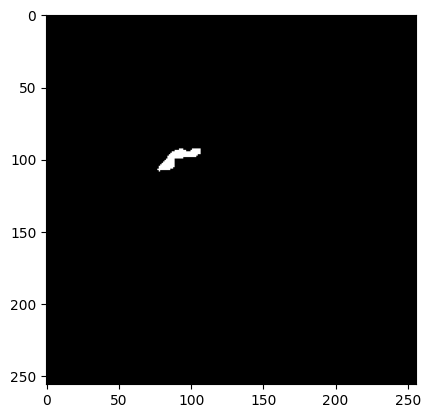

In [ ]:
plt.imshow(cv2.imread(brain_df.mask_path[623]))

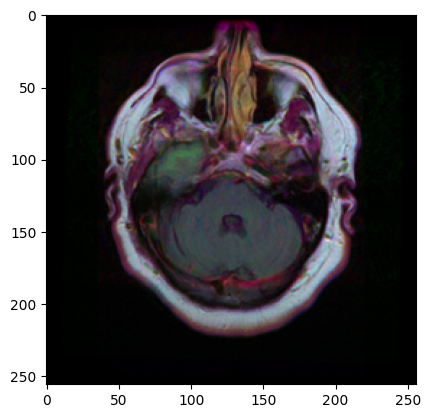

In [ ]:
plt.imshow(cv2.imread(brain_df.image_path[623]))

In [ ]:
cv2.imread(brain_df.mask_path[623]).max()

255

In [ ]:
cv2.imread(brain_df.mask_path[623]).min()

0

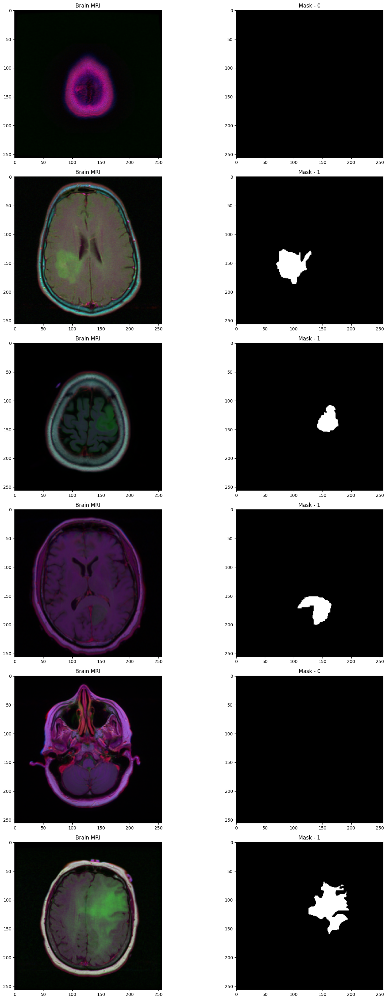

In [ ]:
# Basic visualizations: Visualize the images (MRI and Mask) in the dataset separately
import random
fig, axs = plt.subplots(6,2, figsize=(16,32))
count = 0
for x in range(6):
  i = random.randint(0, len(brain_df)) # select a random index
  axs[count][0].title.set_text("Brain MRI") # set title
  axs[count][0].imshow(cv2.imread(brain_df.image_path[i])) # show MRI
  axs[count][1].title.set_text("Mask - " + str(brain_df['mask'][i])) # plot title on the mask (0 or 1)
  axs[count][1].imshow(cv2.imread(brain_df.mask_path[i])) # Show corresponding mask
  count += 1

fig.tight_layout()

Below we overlay each tumor mask (in red) on top of its MRI scan for a handful of tumor-positive patients — MRI, mask, and the two superimposed — to visually confirm that the masks line up with the actual tumor regions.

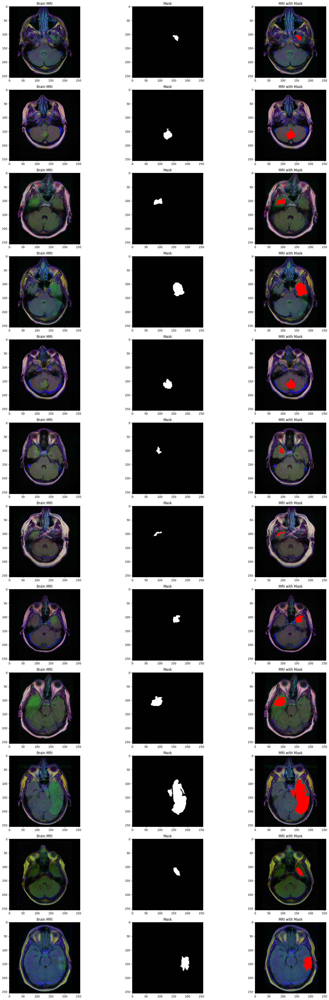

In [ ]:
count = 0
fig, axs = plt.subplots(12, 3, figsize = (20, 50))
for i in range(len(brain_df)):
  if brain_df['mask'][i] ==1 and count <12:
    img = io.imread(brain_df.image_path[i])
    axs[count][0].title.set_text('Brain MRI')
    axs[count][0].imshow(img)

    mask = io.imread(brain_df.mask_path[i])
    axs[count][1].title.set_text('Mask')
    axs[count][1].imshow(mask, cmap = 'gray')


    img[mask == 255] = (255, 0, 0)
    axs[count][2].title.set_text('MRI with Mask')
    axs[count][2].imshow(img)
    count+=1

fig.tight_layout()


## 4. Background — CNNs & ResNet

**Convolutional Neural Networks (CNNs).** Early convolutional layers detect simple, general features (edges, textures); deeper layers compose them into increasingly complex, task-specific patterns, and the final layers perform the actual classification.

**ResNet (Residual Networks).** As CNNs get deeper they suffer from the *vanishing-gradient* problem — gradients shrink toward zero as they back-propagate to early layers, stalling training. ResNet adds **skip connections** that let a block's input bypass it and be added to its output, so gradients flow freely. This is what makes 50–152 layer networks trainable, and why a pre-trained ResNet50 transfers so effectively to our MRI task.

*Reference:* He et al., [Deep Residual Learning for Image Recognition](https://arxiv.org/abs/1512.03385).

Interactive intuition worth a look:
- [Image kernels / convolutions, explained visually](https://setosa.io/ev/image-kernels/)
- [3D CNN visualization](https://adamharley.com/nn_vis/)

## 5. Background — Transfer Learning

Transfer learning reuses a network trained on one task as the starting point for another. Rather than learning millions of ResNet50 weights from scratch on only a few thousand MRI scans, we **freeze** the ImageNet-pretrained backbone (which already knows generic visual features) and train only a small new classification head. This needs less data and compute than training every layer from scratch.

## 6. Stage 1 — ResNet50 Tumor Classifier

We now build the detection model. The workflow is:

1. Prepare the dataframe and cast the `mask` flag to a string label (required by `flow_from_dataframe`).
2. Split into train / validation / test and wire up Keras `ImageDataGenerator`s (rescaling pixels to `[0, 1]`).
3. Load the frozen ResNet50 backbone and attach a custom classification head.
4. Compile with `categorical_crossentropy` + Adam and train with early stopping + checkpointing.

In [ ]:
# Drop the patient id column
brain_df_train = brain_df.drop(columns = ['patient_id'])
brain_df_train.shape

(3929, 3)

In [ ]:
# Convert the data in mask column to string format, to use categorical mode in flow_from_dataframe
# You will get this error message if you comment out the following code line:
# TypeError: If class_mode="categorical", y_col="mask" column values must be type string, list or tuple.
brain_df_train['mask'] = brain_df_train['mask'].apply(lambda x: str(x))

In [ ]:
brain_df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3929 entries, 0 to 3928
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   image_path  3929 non-null   object
 1   mask_path   3929 non-null   object
 2   mask        3929 non-null   object
dtypes: object(3)
memory usage: 92.2+ KB


In [ ]:
# split the data into train and test data

from sklearn.model_selection import train_test_split

train, test = train_test_split(brain_df_train, test_size = 0.15)

In [ ]:
# create a image generator
from keras_preprocessing.image import ImageDataGenerator

# Create a data generator which scales the data from 0 to 1 and makes validation split of 0.15
datagen = ImageDataGenerator(rescale=1./255., validation_split = 0.15)


In [ ]:
train_generator=datagen.flow_from_dataframe(
dataframe=train,
directory= './',
x_col='image_path',
y_col='mask',
subset="training",
batch_size=16,
shuffle=True,
class_mode="categorical",
target_size=(256,256))


valid_generator=datagen.flow_from_dataframe(
dataframe=train,
directory= './',
x_col='image_path',
y_col='mask',
subset="validation",
batch_size=16,
shuffle=True,
class_mode="categorical",
target_size=(256,256))

# Create a data generator for test images
test_datagen=ImageDataGenerator(rescale=1./255.)

test_generator=test_datagen.flow_from_dataframe(
dataframe=test,
directory= './',
x_col='image_path',
y_col='mask',
batch_size=16,
shuffle=False,
class_mode='categorical',
target_size=(256,256))



Found 2839 validated image filenames belonging to 2 classes.
Found 500 validated image filenames belonging to 2 classes.
Found 590 validated image filenames belonging to 2 classes.


### Frozen ResNet50 backbone + custom head

We load ResNet50 with ImageNet weights and no top layers, freeze it, then bolt on our own head ending in a 2-way softmax (tumor / no-tumor), so that only the head is trained. Note: the freeze loop below sets `layers.trainable` (the Keras module) instead of `layer.trainable`, so it does not actually freeze anything; `models.py` has the corrected loop.

In [ ]:
# Get the ResNet50 base model
basemodel = ResNet50(weights = 'imagenet', include_top = False, input_tensor = Input(shape=(256, 256, 3)))

In [ ]:
basemodel.summary()

Model: "resnet50"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 256, 256, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv1_pad (ZeroPadding2D)      (None, 262, 262, 3)  0           ['input_1[0][0]']                
                                                                                                  
 conv1_conv (Conv2D)            (None, 128, 128, 64  9472        ['conv1_pad[0][0]']              
                                )                                                                 
                                                                                           

In [ ]:
# freeze the model weights

for layer in basemodel.layers:
  layers.trainable = False

In [ ]:
# Add classification head to the base model

headmodel = basemodel.output
headmodel = AveragePooling2D(pool_size = (4,4))(headmodel)
headmodel = Flatten(name= 'flatten')(headmodel)
headmodel = Dense(256, activation = "relu")(headmodel)
headmodel = Dropout(0.3)(headmodel)#
headmodel = Dense(256, activation = "relu")(headmodel)
headmodel = Dropout(0.3)(headmodel)
#headmodel = Dense(256, activation = "relu")(headmodel)
#headmodel = Dropout(0.3)(headmodel)
headmodel = Dense(2, activation = 'softmax')(headmodel)

model = Model(inputs = basemodel.input, outputs = headmodel)

In [ ]:
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 256, 256, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv1_pad (ZeroPadding2D)      (None, 262, 262, 3)  0           ['input_1[0][0]']                
                                                                                                  
 conv1_conv (Conv2D)            (None, 128, 128, 64  9472        ['conv1_pad[0][0]']              
                                )                                                                 
                                                                                              

In [ ]:
# compile the model

model.compile(loss = 'categorical_crossentropy', optimizer='adam', metrics= ["accuracy"])

In [ ]:
# use early stopping to exit training if validation loss is not decreasing even after certain epochs (patience)
earlystopping = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=20)

# save the best model with least validation loss
checkpointer = ModelCheckpoint(filepath="classifier-resnet-weights.hdf5", verbose=1, save_best_only=True)

Training runs on a GPU and takes a while, so the `model.fit` call is left commented out here. The evaluation section below instead loads the pre-trained weights that came with the course (`weights.hdf5`), so every result in this notebook comes from those weights, not from a training run here.

In [ ]:
#history = model.fit(train_generator, steps_per_epoch= train_generator.n // 16, epochs = 1, validation_data= valid_generator, validation_steps= valid_generator.n // 16, callbacks=[checkpointer, earlystopping])

In [ ]:
# # save the model architecture to json file for future use

# model_json = model.to_json()
# with open("classifier-resnet-model.json","w") as json_file:
#   json_file.write(model_json)

## 7. Evaluating the Classifier

We load the trained architecture (`resnet-50-MRI.json`) and its best weights (`weights.hdf5`), run predictions on the held-out test set, and report accuracy, a confusion matrix, and a full precision / recall / F1 report.

In [ ]:
# Load pretrained model (instead of training the model for a long time)
with open('resnet-50-MRI.json', 'r') as json_file:
    json_savedModel= json_file.read()
# load the model
model = tf.keras.models.model_from_json(json_savedModel)
model.load_weights('weights.hdf5')
model.compile(loss = 'categorical_crossentropy', optimizer='adam', metrics= ["accuracy"])

In [ ]:
# make prediction

test_predict = model.predict(test_generator, steps = test_generator.n // 16, verbose =1)

36/36 [==============================] - 511s 14s/step


In [ ]:
test_predict.shape

(576, 2)

In [ ]:
test_predict

array([[9.6000278e-08, 9.9999982e-01],
       [9.9999994e-01, 6.1641425e-10],
       [9.9999958e-01, 3.0901316e-07],
       ...,
       [3.0188871e-04, 9.9969816e-01],
       [2.2025642e-07, 9.9999970e-01],
       [9.9964976e-01, 3.5025759e-04]], dtype=float32)

In [ ]:
# Obtain the predicted class from the model prediction
predict = []

for i in test_predict:
  predict.append(str(np.argmax(i)))

predict = np.asarray(predict)

In [ ]:
predict

array(['1', '0', '0', '0', '0', '1', '0', '1', '0', '0', '0', '0', '0',
       '1', '1', '0', '1', '0', '0', '0', '0', '0', '0', '0', '1', '1',
       '0', '0', '0', '0', '0', '0', '1', '0', '0', '0', '1', '1', '0',
       '1', '1', '0', '0', '0', '0', '0', '0', '0', '0', '1', '0', '1',
       '0', '0', '1', '1', '0', '1', '0', '0', '0', '1', '1', '1', '0',
       '0', '0', '0', '0', '1', '1', '0', '1', '0', '0', '0', '1', '1',
       '0', '0', '0', '0', '1', '0', '0', '0', '0', '0', '0', '1', '0',
       '0', '1', '1', '0', '1', '0', '1', '0', '0', '0', '0', '0', '0',
       '0', '0', '0', '1', '1', '0', '1', '1', '0', '1', '1', '0', '0',
       '0', '1', '0', '0', '0', '1', '0', '0', '0', '1', '0', '1', '0',
       '0', '0', '0', '1', '0', '0', '1', '0', '0', '0', '1', '0', '0',
       '0', '0', '0', '1', '1', '0', '0', '0', '1', '0', '1', '1', '1',
       '1', '0', '0', '1', '0', '0', '0', '0', '0', '1', '0', '1', '0',
       '0', '1', '1', '1', '0', '0', '0', '0', '0', '0', '1', '0

In [ ]:
# since we have used test generator, it limited the images to len(predict), due to batch size
original = np.asarray(test['mask'])[:len(predict)]
len(original)

576

In [ ]:
# Obtain the accuracy of the model
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(original, predict)
accuracy

0.9809027777777778

<Axes: >

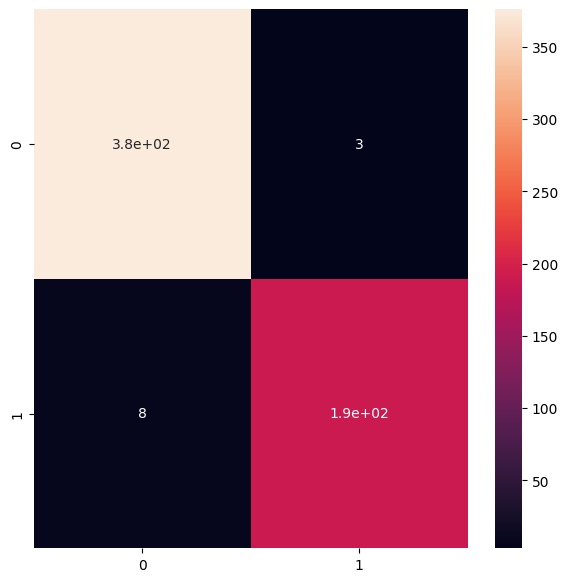

In [ ]:
# plot the confusion matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(original, predict)
plt.figure(figsize = (7,7))
sns.heatmap(cm, annot=True)

### Classification report

Precision, recall and F1 for both classes:

In [ ]:
from sklearn.metrics import classification_report

report = classification_report(original, predict, labels = [0,1])
print(report)

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       379
           1       0.98      0.96      0.97       197

   micro avg       0.98      0.98      0.98       576
   macro avg       0.98      0.98      0.98       576
weighted avg       0.98      0.98      0.98       576



**Result:** with the course's pre-trained weights, the classifier scores 98.1% accuracy on 576 test slices (the last 14 of the 590 are dropped by `steps = n // 16`), with precision and recall between 0.96 and 0.99 for both classes. Treat this as optimistic: the split is random over slices rather than patients, and the weights were trained on a split we can't see, so some of these test slices may have been in their training data.

## 8. Stage 2 — ResUNet for Tumor Localization

Detection tells us *whether* a tumor exists; segmentation tells us *where*. **Image segmentation** classifies every pixel, producing a mask that outlines the tumor exactly.

We use a **ResUNet** — a U-Net encoder–decoder in which each block is a *residual* block. The encoder compresses the image into a compact feature representation; the decoder upsamples it back to full resolution, using **skip connections** to reinject the fine spatial detail lost during downsampling. The residual blocks bring ResNet's easy-gradient-flow benefit to the U-Net shape.

**ResUNet architecture at a glance:**

```
Encoder (downsampling)                          Decoder (upsampling)
  Stage 1  Conv x2   (16)  ------ skip ------>  concat -> ResBlock (16)
  Stage 2  ResBlock  (32)  ------ skip ------>  concat -> ResBlock (32)
  Stage 3  ResBlock  (64)  ------ skip ------>  concat -> ResBlock (64)
  Stage 4  ResBlock (128)  ------ skip ------>  concat -> ResBlock (128)
              \                                        /
               ------>  Bottleneck ResBlock (256)  ----
  Final: Conv 1x1 + sigmoid  ->  tumor mask (256 x 256 x 1)
```

Each arrow is a **skip connection** that copies encoder feature maps straight into the matching decoder stage, so the model keeps precise tumor boundaries.

### Building the ResUNet

We assemble the network from two reusable pieces defined below: a **residual block** (`resblock`) and an **upsample-and-concatenate** helper (`upsample_concat`) for the skip connections.

The segmentation model only ever sees scans that *contain* a tumor, so we first filter the dataframe down to the 1,373 tumor-positive rows before splitting.

In [ ]:
# Get the dataframe containing MRIs which have masks associated with them.
brain_df_mask = brain_df[brain_df['mask'] == 1]
brain_df_mask.shape

(1373, 4)

In [ ]:
# split the data into train and test data

from sklearn.model_selection import train_test_split

X_train, X_val = train_test_split(brain_df_mask, test_size=0.15)
X_test, X_val = train_test_split(X_val, test_size=0.5)

In [ ]:
# create separate list for imageId, classId to pass into the generator

train_ids = list(X_train.image_path)
train_mask = list(X_train.mask_path)

val_ids = list(X_val.image_path)
val_mask= list(X_val.mask_path)

Because the masks need custom loading and normalisation, we stream data through the `DataGenerator` from [`utilities.py`](utilities.py) instead of Keras' `ImageDataGenerator`.

In [ ]:
# Utilities file contains the code for custom loss function and custom data generator
from utilities import DataGenerator

# create image generators

training_generator = DataGenerator(train_ids,train_mask)
validation_generator = DataGenerator(val_ids,val_mask)

**Residual block.** Two conv layers on the main path plus a `1x1` conv on the shortcut, added together — the ResNet identity trick that keeps gradients healthy inside the U-Net.

In [ ]:
def resblock(X, f):


  # make a copy of input
  X_copy = X

  # main path
  # Read more about he_normal: https://medium.com/@prateekvishnu/xavier-and-he-normal-he-et-al-initialization-8e3d7a087528

  X = Conv2D(f, kernel_size = (1,1) ,strides = (1,1),kernel_initializer ='he_normal')(X)
  X = BatchNormalization()(X)
  X = Activation('relu')(X)

  X = Conv2D(f, kernel_size = (3,3), strides =(1,1), padding = 'same', kernel_initializer ='he_normal')(X)
  X = BatchNormalization()(X)

  # Short path
  # Read more here: https://towardsdatascience.com/understanding-and-coding-a-resnet-in-keras-446d7ff84d33

  X_copy = Conv2D(f, kernel_size = (1,1), strides =(1,1), kernel_initializer ='he_normal')(X_copy)
  X_copy = BatchNormalization()(X_copy)

  # Adding the output from main path and short path together

  X = Add()([X,X_copy])
  X = Activation('relu')(X)

  return X

In [ ]:
# function to upscale and concatenate the values passsed
def upsample_concat(x, skip):
  x = UpSampling2D((2,2))(x)
  merge = Concatenate()([x, skip])

  return merge

**Assembling the full network.** Four downsampling stages (16 -> 32 -> 64 -> 128 filters) feed a 256-filter bottleneck, then four symmetric upsampling stages each concatenate the matching encoder features before a final `1x1` sigmoid conv produces the mask.

In [ ]:
input_shape = (256,256,3)

# Input tensor shape
X_input = Input(input_shape)

# Stage 1
conv1_in = Conv2D(16,3,activation= 'relu', padding = 'same', kernel_initializer ='he_normal')(X_input)
conv1_in = BatchNormalization()(conv1_in)
conv1_in = Conv2D(16,3,activation= 'relu', padding = 'same', kernel_initializer ='he_normal')(conv1_in)
conv1_in = BatchNormalization()(conv1_in)
pool_1 = MaxPool2D(pool_size = (2,2))(conv1_in)

# Stage 2
conv2_in = resblock(pool_1, 32)
pool_2 = MaxPool2D(pool_size = (2,2))(conv2_in)

# Stage 3
conv3_in = resblock(pool_2, 64)
pool_3 = MaxPool2D(pool_size = (2,2))(conv3_in)

# Stage 4
conv4_in = resblock(pool_3, 128)
pool_4 = MaxPool2D(pool_size = (2,2))(conv4_in)

# Stage 5 (Bottle Neck)
conv5_in = resblock(pool_4, 256)

# Upscale stage 1
up_1 = upsample_concat(conv5_in, conv4_in)
up_1 = resblock(up_1, 128)

# Upscale stage 2
up_2 = upsample_concat(up_1, conv3_in)
up_2 = resblock(up_2, 64)

# Upscale stage 3
up_3 = upsample_concat(up_2, conv2_in)
up_3 = resblock(up_3, 32)

# Upscale stage 4
up_4 = upsample_concat(up_3, conv1_in)
up_4 = resblock(up_4, 16)

# Final Output
output = Conv2D(1, (1,1), padding = "same", activation = "sigmoid")(up_4)

model_seg = Model(inputs = X_input, outputs = output )


In [ ]:
model_seg.summary()

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_2 (InputLayer)           [(None, 256, 256, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 256, 256, 16  448         ['input_2[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization (BatchNorm  (None, 256, 256, 16  64         ['conv2d[0][0]']                 
 alization)                     )                                                           

## 9. Training the ResUNet

### Loss function — Focal Tversky

Tumor pixels are rare, so an ordinary loss can score well by simply predicting mostly background. We instead use the **Focal Tversky loss**, which (a) weights false negatives more heavily than false positives via the Tversky index, and (b) focuses the gradient on hard, mis-segmented regions via a focal exponent. The implementation lives in [`utilities.py`](utilities.py) and follows:

> Abraham & Khan, *A Novel Focal Tversky Loss Function with Improved Attention U-Net for Lesion Segmentation*, 2018 — arXiv:1810.07842.

In [ ]:
# Utilities file contains the code for custom loss function and custom data generator

from utilities import focal_tversky, tversky_loss, tversky

In [ ]:
# Compile the model
adam = tf.keras.optimizers.Adam(lr = 0.05, epsilon = 0.1)
model_seg.compile(optimizer = adam, loss = focal_tversky, metrics = [tversky])

In [ ]:
# use early stopping to exit training if validation loss is not decreasing even after certain epochs (patience)
earlystopping = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=20)

# save the best model with lower validation loss
checkpointer = ModelCheckpoint(filepath="ResUNet-weights.hdf5", verbose=1, save_best_only=True)

In [ ]:
#history = model_seg.fit(training_generator, epochs = 1, validation_data = validation_generator, callbacks = [checkpointer, earlystopping])

In [ ]:
# save the model architecture to json file for future use

# model_json = model_seg.to_json()
# with open("ResUNet-model.json","w") as json_file:
#   json_file.write(model_json)

## 10. Evaluating the Segmentation Model

Finally we run the **complete two-stage pipeline** end-to-end: the ResNet50 classifier screens each test scan, and every scan it flags is segmented by the ResUNet. The `prediction` helper in [`utilities.py`](utilities.py) does exactly this and returns, per scan, the predicted mask and a has-tumor flag.

In [ ]:
from utilities import focal_tversky, tversky_loss, tversky

with open('ResUNet-MRI.json', 'r') as json_file:
    json_savedModel= json_file.read()

# load the model architecture
model_seg = tf.keras.models.model_from_json(json_savedModel)
model_seg.load_weights('weights_seg.hdf5')
adam = tf.keras.optimizers.Adam(lr = 0.05, epsilon = 0.1)
model_seg.compile(optimizer = adam, loss = focal_tversky, metrics = [tversky])

In [ ]:
# Utilities file contains the code for custom loss function and custom data generator
from utilities import prediction

# making prediction
image_id, mask, has_mask = prediction(test, model, model_seg)

1/1 [==============================] - 0s 203ms/step


In [ ]:
# creating a dataframe for the result
df_pred = pd.DataFrame({'image_path': image_id,'predicted_mask': mask,'has_mask': has_mask})
df_pred

,image_path,predicted_mask,has_mask
0,TCGA_DU_A5TS_19970726/TCGA_DU_A5TS_19970726_15...,"[[[[8.478727e-07], [3.6482706e-06], [1.0175344...",1
1,TCGA_DU_6404_19850629/TCGA_DU_6404_19850629_10...,No mask,0
2,TCGA_FG_7634_20000128/TCGA_FG_7634_20000128_11...,No mask,0
3,TCGA_FG_6691_20020405/TCGA_FG_6691_20020405_35...,No mask,0
4,TCGA_FG_6690_20020226/TCGA_FG_6690_20020226_39...,No mask,0
...,...,...,...
585,TCGA_HT_7874_19950902/TCGA_HT_7874_19950902_20...,No mask,0
586,TCGA_FG_8189_20030516/TCGA_FG_8189_20030516_8.tif,No mask,0
587,TCGA_HT_7877_19980917/TCGA_HT_7877_19980917_21...,"[[[[7.535802e-07], [2.6984142e-06], [5.3166646...",1
588,TCGA_DU_6407_19860514/TCGA_DU_6407_19860514_53...,No mask,0


In [ ]:
# Merge the dataframe containing predicted results with the original test data.
df_pred = test.merge(df_pred, on = 'image_path')
df_pred.head()

,image_path,mask_path,mask,predicted_mask,has_mask
0,TCGA_DU_A5TS_19970726/TCGA_DU_A5TS_19970726_15...,TCGA_DU_A5TS_19970726/TCGA_DU_A5TS_19970726_15...,1,"[[[[8.478727e-07], [3.6482706e-06], [1.0175344...",1
1,TCGA_DU_6404_19850629/TCGA_DU_6404_19850629_10...,TCGA_DU_6404_19850629/TCGA_DU_6404_19850629_10...,0,No mask,0
2,TCGA_FG_7634_20000128/TCGA_FG_7634_20000128_11...,TCGA_FG_7634_20000128/TCGA_FG_7634_20000128_11...,0,No mask,0
3,TCGA_FG_6691_20020405/TCGA_FG_6691_20020405_35...,TCGA_FG_6691_20020405/TCGA_FG_6691_20020405_35...,0,No mask,0
4,TCGA_FG_6690_20020226/TCGA_FG_6690_20020226_39...,TCGA_FG_6690_20020226/TCGA_FG_6690_20020226_39...,0,No mask,0


The grid below compares, for each tumor scan: the MRI, the ground-truth mask, the AI-predicted mask, the MRI with the ground-truth mask overlaid (red), and the MRI with the AI prediction overlaid (green).

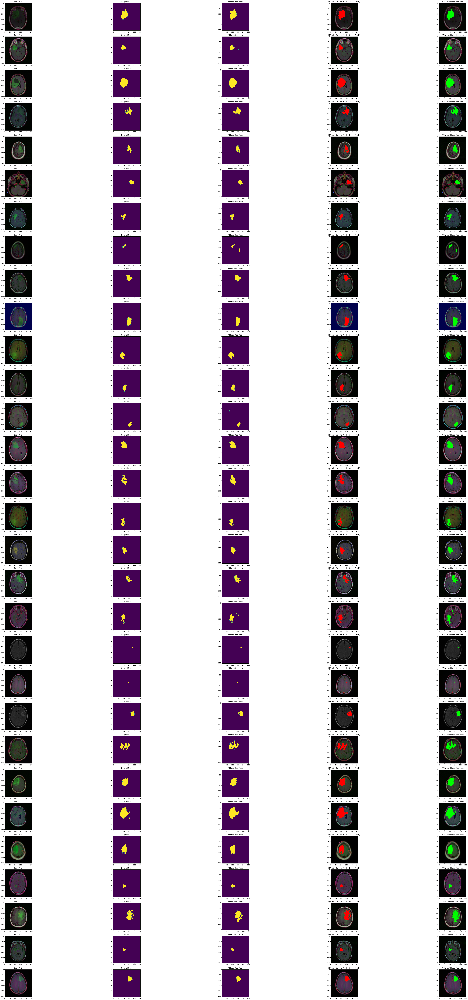

In [ ]:
count = 0
fig, axs = plt.subplots(30, 5, figsize=(60, 100))
for i in range(len(df_pred)):
  if df_pred['has_mask'][i] == 1 and count < 30:
    # read the images and convert them to RGB format
    img = io.imread(df_pred.image_path[i])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axs[count][0].title.set_text("Brain MRI")
    axs[count][0].imshow(img)

    # Obtain the mask for the image
    mask = io.imread(df_pred.mask_path[i])
    axs[count][1].title.set_text("Original Mask")
    axs[count][1].imshow(mask)

    # Obtain the predicted mask for the image
    predicted_mask = np.asarray(df_pred.predicted_mask[i])[0].squeeze().round()
    axs[count][2].title.set_text("AI Predicted Mask")
    axs[count][2].imshow(predicted_mask)

    # Apply the mask to the image 'mask==255'
    img[mask == 255] = (255, 0, 0)
    axs[count][3].title.set_text("MRI with Original Mask (Ground Truth)")
    axs[count][3].imshow(img)

    img_ = io.imread(df_pred.image_path[i])
    img_ = cv2.cvtColor(img_, cv2.COLOR_BGR2RGB)
    img_[predicted_mask == 1] = (0, 255, 0)
    axs[count][4].title.set_text("MRI with AI Predicted Mask")
    axs[count][4].imshow(img_)
    count += 1

fig.tight_layout()

## Results & Conclusion

| Stage | Model | Metric | Score |
| --- | --- | --- | --- |
| Detection | ResNet50 (course's pre-trained weights) | Test accuracy (576 slices, slice-level split) | 98.1% |
| Detection | ResNet50 | F1 (no-tumor / tumor) | 0.99 / 0.97 |
| Localization | ResUNet + Focal Tversky | Qualitative only (no Dice/IoU computed) | See the grid above |

**Takeaways**

- A two-stage *classify-then-segment* cascade only runs segmentation on the scans the classifier flags.
- Transfer learning from ImageNet makes a 50-layer classifier trainable on just a few thousand medical images.
- The Focal Tversky loss targets the heavy imbalance between tumor and background pixels (no ablation was run here).

**Limitations & future work.** The evaluated weights came with the course and were not trained in this notebook, and the test split is slice-level, so slices from the same patient can sit in both train and test. Trained on a single dataset/modality (LGG FLAIR) and not validated for clinical use. Next steps: a patient-level split with a segmentation metric (Dice/IoU), k-fold cross-validation, hyperparameter tuning, test-time augmentation, and a Streamlit/Flask demo for interactive inference. Full write-up in [`docs/PROJECT_REPORT.md`](docs/PROJECT_REPORT.md).

---
*Built by Vinayak Mokashi.*